# Project 11: Inventory Image Tagging
## Phase 2: a small CNN, an ablation study and a hybrid

Phase 1 described each picture with fixed numbers (pixels, HOG) and used classical classifiers. Here a small CNN learns its own description, and we test whether that helps the categories Phase 1 mixed up: Shirt, T-shirt, Pullover and Coat.

This notebook reads the saved Phase 2 results in `reports/phase2/`. It does not retrain anything. It needs PyTorch (`requirements-phase2.txt`) but no dataset download.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display, Image as Show
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.inventory_tagging_dl import cnn
OUT = ROOT / "reports/phase2"
frozen = json.loads((OUT / "frozen.json").read_text())
summary = json.loads((OUT / "test/summary.json").read_text())
CLASSES = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")
print("PyTorch", torch.__version__, "| final CNN:", frozen["cnn_config"], frozen["cnn_settings"])

PyTorch 2.14.1 | final CNN: light_dropout {'blocks': 2, 'batch_norm': True, 'dropout': 0.2, 'augment': True}


## 1. The network

Each convolution block slides 3x3 filters over the picture (they learn edges and corners), applies batch normalisation and ReLU, then max pooling halves the width and height: 28 to 14 to 7. Two dense layers turn the 64 x 7 x 7 map into a 64-number summary of the picture. Dropout switches off a share of units during training only. A final linear layer gives ten scores.

The 64-number summary is what the hybrid model hands to a classical classifier.

In [2]:
model = cnn.SmallCNN(**frozen["cnn_settings"])
print(model)
x = torch.zeros(1, 1, 28, 28)
for layer in model.features:
    x = layer(x)
    if layer.__class__.__name__ == "MaxPool2d":
        print("after pooling:", tuple(x.shape))
print("trainable parameters:", f"{cnn.count_parameters(model):,}", "| without the last layer:", f"{cnn.count_parameters(model, head=False):,}")

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (embed): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
  )
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=64, out_features=10, bias=True)
  )
)
after pooling: (1, 3

## 2. Augmentation

Training pictures are randomly mirrored and shifted by up to 2 pixels. A mirrored or nudged shirt is still a shirt, so the network sees more variety. Test pictures are never changed. Top row: ten training examples. Bottom row: one random augmentation of each.

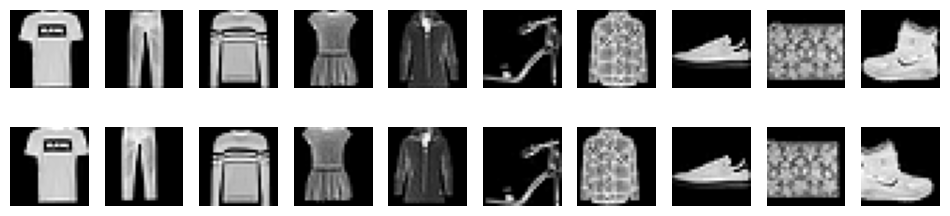

In [3]:
import matplotlib.pyplot as plt
files = sorted((ROOT / "assets/examples").glob("*.png"))
pictures = np.stack([np.asarray(Image.open(f).convert("L")) for f in files])
original = cnn.to_tensor(pictures)
torch.manual_seed(1)
changed = cnn.augment(original)
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(10):
    axes[0][i].imshow(original[i, 0], cmap="gray"); axes[1][i].imshow(changed[i, 0], cmap="gray")
    axes[0][i].axis("off"); axes[1][i].axis("off")
plt.show()

## 3. Ablation study

We remove one ingredient at a time from the full model and train each version with three seeds on the same 48,000 pictures. Scores are on the 12,000 validation pictures. Bars in the figure show the average and the seed-to-seed spread. If two versions differ by less than that spread, we do not claim one is better.

`light_dropout` was added after the first runs showed that dropout 0.4 hurt. It was judged on validation data only.

,config,validation_macro_f1_mean,validation_macro_f1_std,validation_accuracy_mean,best_epoch_mean,parameters
0,full,0.9202,0.0036,0.9203,24.0000,429450
1,no_batch_norm,0.9195,0.0018,0.9199,28.0000,429258
2,no_dropout,0.9282,0.0022,0.9283,21.3333,429450
3,light_dropout,0.9264,0.0033,0.9265,26.3333,429450
4,no_augmentation,0.9254,0.0033,0.9258,10.6667,429450
5,three_blocks,0.9215,0.0049,0.9218,16.3333,249610
6,plain,0.9258,0.0023,0.9260,15.6667,429258


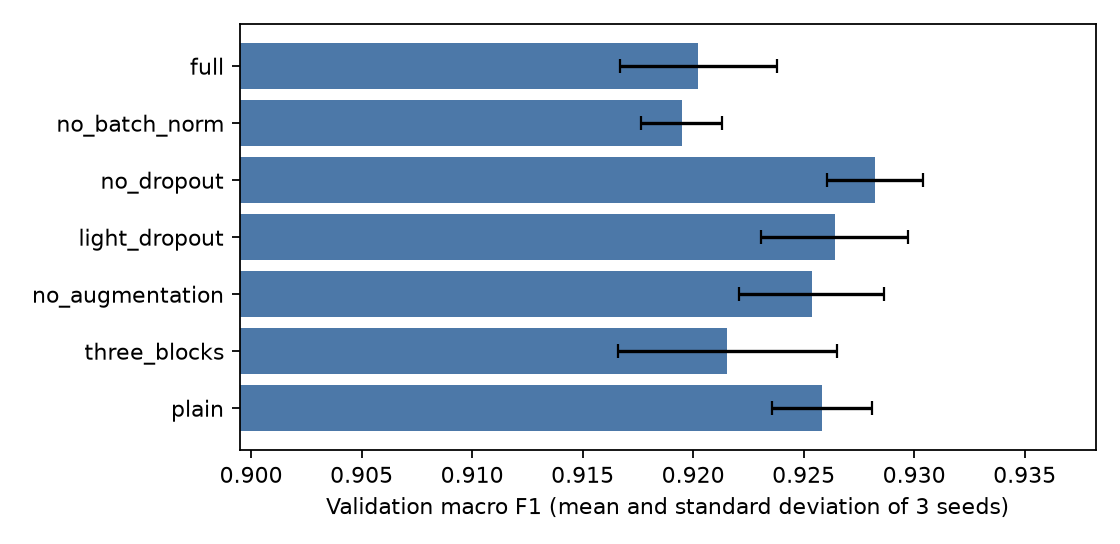

Final CNN: light_dropout | rule: highest mean validation macro F1 over 3 seeds among configurations that use dropout (the brief asks for it)
Best overall: no_dropout 0.9282 vs selected 0.9264 | seed spread of selected 0.0033


In [4]:
table = pd.read_csv(OUT / "ablation_summary.csv")
display(table[["config", "validation_macro_f1_mean", "validation_macro_f1_std", "validation_accuracy_mean", "best_epoch_mean", "parameters"]].round(4))
display(Show(filename=str(OUT / "figures/ablation.png")))
selection = json.loads((OUT / "selection.json").read_text())
print("Final CNN:", selection["config"], "| rule:", selection["rule"])
print("Best overall:", selection["best_overall_config"], round(selection["best_overall_validation_macro_f1_mean"], 4),
      "vs selected", round(selection["validation_macro_f1_mean"], 4), "| seed spread of selected", round(selection["seed_std_of_selected"], 4))

## 4. Early stopping

Training loss keeps falling, while validation loss eventually stops improving. We stop after 5 epochs without improvement and keep the weights from the best epoch. Only validation data decides this.

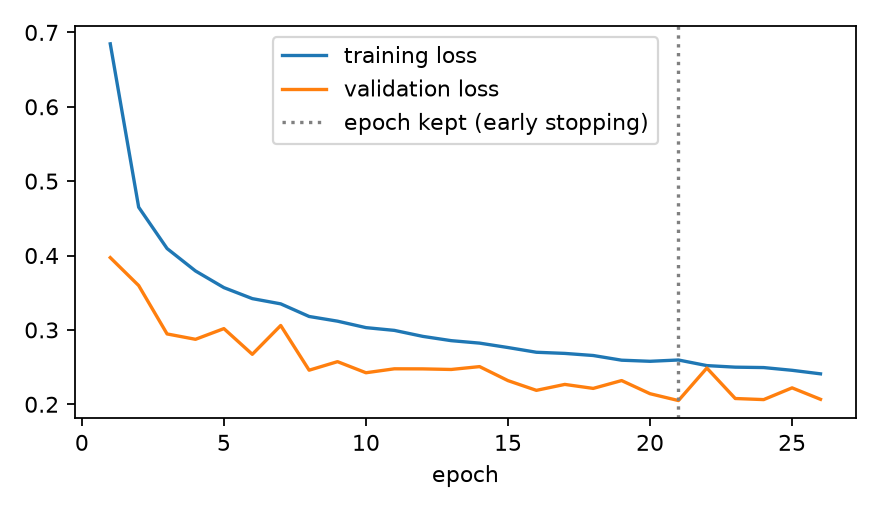

In [5]:
display(Show(filename=str(OUT / "figures/learning_curves.png")))

## 5. Hybrid: CNN features into a classical classifier

The CNN's 64-number summary is given to a Phase 1 classifier instead of the CNN's own last layer. The classifier is fitted on training pictures only. As a control, we do the same with features from an untrained CNN of the same shape.

In [6]:
hv = pd.read_csv(OUT / "hybrid_validation.csv")
display(hv.groupby(["family", "parameters"])[["validation_accuracy", "validation_macro_f1"]].mean().round(4))
hs = json.loads((OUT / "hybrid_selection.json").read_text())
print("Selected:", hs["family"], hs["parameters"])
print("validation macro F1  hybrid:", round(hs["validation_macro_f1_mean"], 4),
      "| CNN's own last layer:", round(hs["cnn_own_head_validation_macro_f1_mean"], 4),
      "| untrained-CNN features:", round(hs["untrained_cnn_features_validation_macro_f1_mean"], 4))

validation_accuracy  \
family              parameters                                                      
linear_svm          {"C": 0.1}                                             0.9317   
                    {"C": 1.0}                                             0.9313   
logistic_regression {"C": 0.1}                                             0.9317   
                    {"C": 1.0}                                             0.9313   
random_forest       {"n_estimators": 200, "max_depth": 25}                 0.9324   
                    {"n_estimators": 400, "max_depth": null}               0.9324   

                                                              validation_macro_f1  
family              parameters                                                     
linear_svm          {"C": 0.1}                                             0.9315  
                    {"C": 1.0}                                             0.9312  
logistic_regression {"C": 0.1}                                             0.9316  
                    {"C": 1.0}                                             0.9312  
random_forest       {"n_estimators": 200, "max_depth": 25}                 0.9323  
                    {"n_estimators": 400, "max_depth": null}               0.9324

Selected: random_forest {'n_estimators': 400, 'max_depth': None}
validation macro F1  hybrid: 0.9324 | CNN's own last layer: 0.9264 | untrained-CNN features: 0.7944


## 6. Final test, run once

The settings above were frozen in `reports/phase2/frozen.json` before the 10,000 official test pictures were scored. The CNN and the hybrid were each trained with three seeds.

,name,test_accuracy,test_macro_f1
9,hybrid cnn + random_forest (mean of 3 seeds),0.9249,0.9246
8,cnn (mean of 3 seeds),0.9198,0.9194
0,pixels_random_forest,0.8761,0.8747
1,pixels_knn,0.8509,0.8515
6,hog_random_forest,0.8459,0.8455
4,hog_logistic_regression,0.8455,0.8450
5,hog_linear_svm,0.8401,0.8385
3,pixels_linear_svm,0.8397,0.8373
2,pixels_logistic_regression,0.8396,0.8390
7,hog_knn,0.8381,0.8382


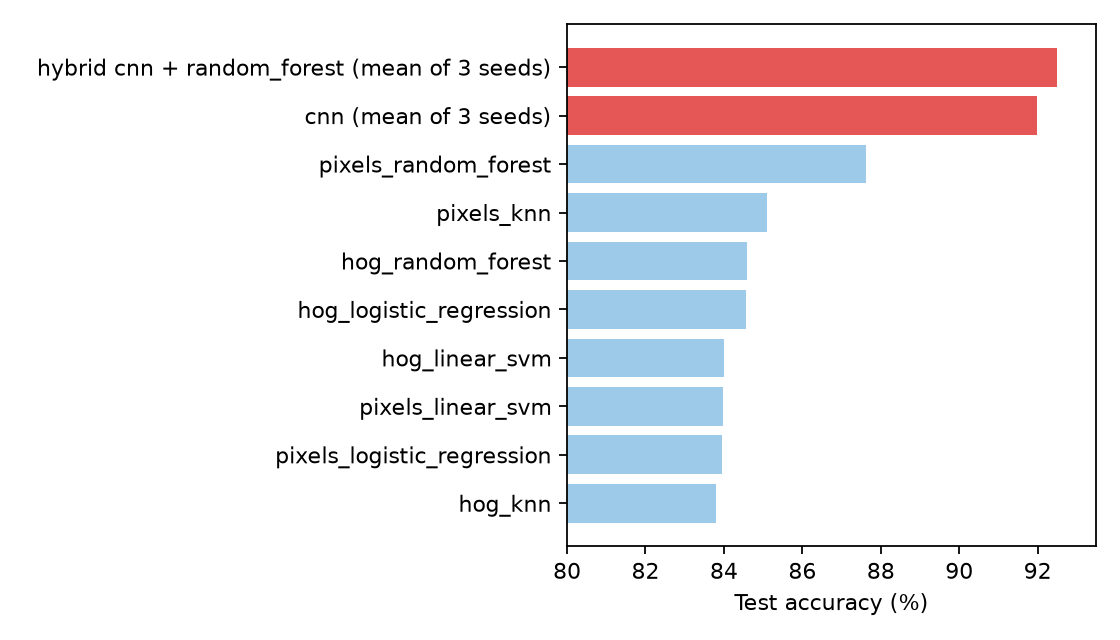

cnn_vs_phase1_seed42: accuracy difference +4.10 points, 95% interval [+3.52, +4.67]
hybrid_vs_cnn_seed42: accuracy difference +0.60 points, 95% interval [+0.28, +0.94]


In [7]:
comparison = pd.read_csv(OUT / "test/comparison.csv")
display(comparison.sort_values("test_accuracy", ascending=False).round(4))
display(Show(filename=str(OUT / "figures/test_comparison.png")))
for key in ("cnn_vs_phase1_seed42", "hybrid_vs_cnn_seed42"):
    d = summary[key]
    print(f"{key}: accuracy difference {d['difference']*100:+.2f} points, 95% interval [{d['low']*100:+.2f}, {d['high']*100:+.2f}]")

## 7. Does the CNN separate the similar categories better?

Recall is the share of each category found. The table counts how often one upper-body category is mistaken for another on the test set (seed 42 for the CNN and the hybrid).

,category,phase1_pixels_random_forest,cnn_mean,hybrid_mean
0,T-shirt/top,0.852,0.889,0.885
1,Trouser,0.959,0.988,0.988
2,Pullover,0.802,0.887,0.896
3,Dress,0.910,0.928,0.932
4,Coat,0.822,0.870,0.882
5,Sandal,0.954,0.975,0.982
6,Shirt,0.592,0.736,0.757
7,Sneaker,0.947,0.971,0.976
8,Bag,0.975,0.988,0.989
9,Ankle boot,0.948,0.967,0.962


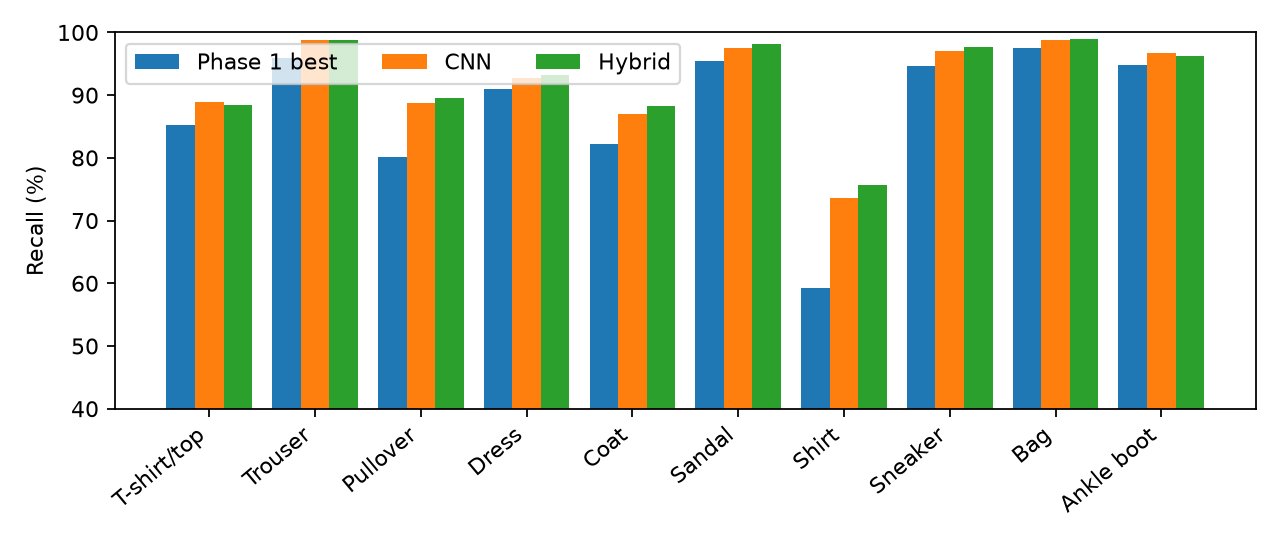

,true,predicted,phase1,cnn,hybrid
9,Shirt,T-shirt/top,149,128,95
10,Shirt,Pullover,124,80,51
4,Pullover,Coat,116,33,37
7,Coat,Pullover,91,60,44
11,Shirt,Coat,85,78,71
2,T-shirt/top,Shirt,83,59,81
5,Pullover,Shirt,58,30,48
8,Coat,Shirt,49,40,45


In [8]:
display(pd.read_csv(OUT / "test/per_class_recall.csv").round(3))
display(Show(filename=str(OUT / "figures/recall_comparison.png")))
display(pd.read_csv(OUT / "test/upper_body_confusions.csv").sort_values("phase1", ascending=False).head(8))

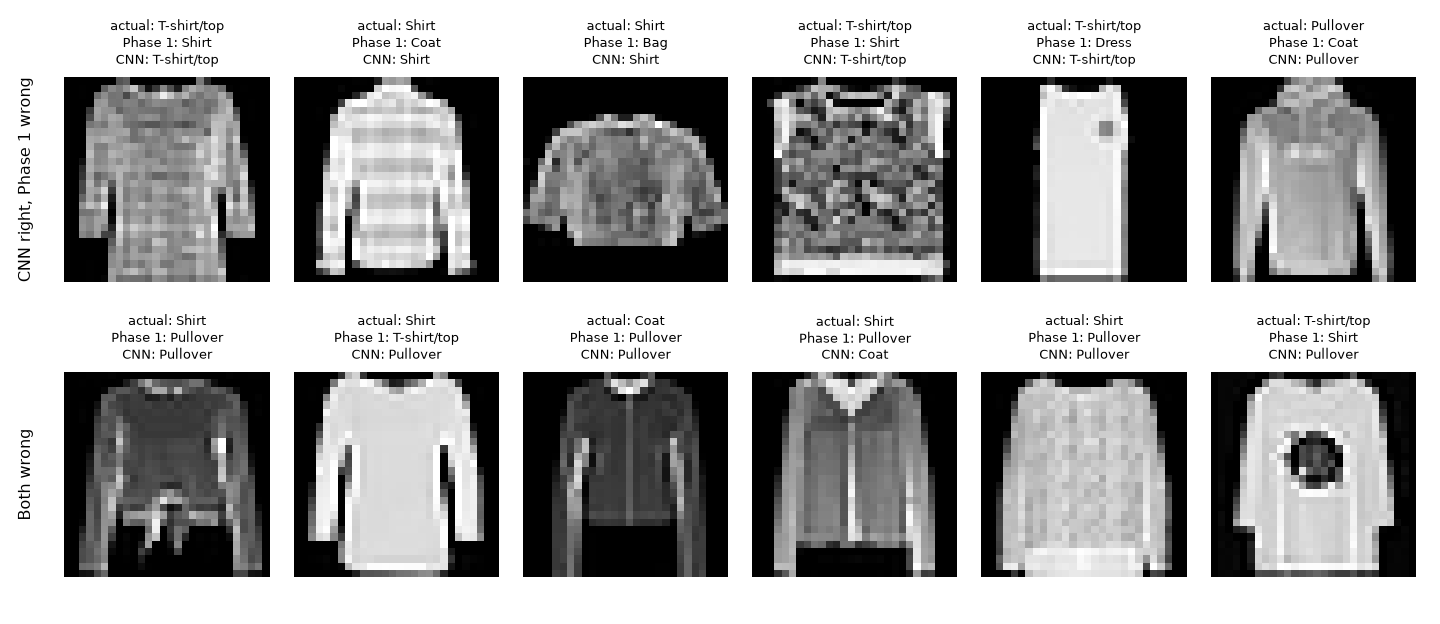

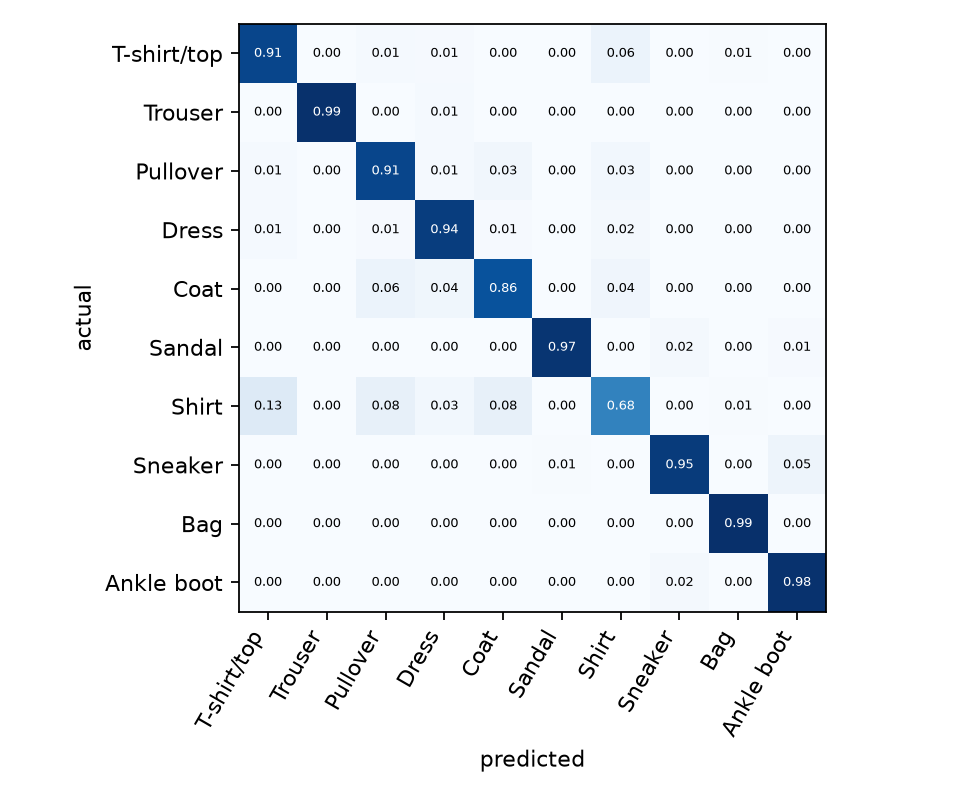

In [9]:
display(Show(filename=str(OUT / "figures/error_examples.png")))
display(Show(filename=str(OUT / "figures/confusion_cnn.png")))

## 8. Cost

Timed on the CPU with two threads, from a 28x28 picture to a label, like Phase 1. The CNN's last layer is quick; in the hybrid, the 400-tree Random Forest dominates the time.

In [10]:
costs = summary["costs"]
display(pd.DataFrame({"CNN": costs["cnn"], "Hybrid": {k: v for k, v in costs["hybrid"].items() if k != "classifier"}}))
print("Hybrid classifier size:", costs["hybrid"]["classifier"])

,CNN,Hybrid
single_ms_median,1.668750e-01,25.878854
single_ms_p95,2.027066e-01,29.981571
batch_ms_per_image,8.838708e-02,0.290636
batch_images_per_second,1.131387e+04,3440.728216
parameters,4.294500e+05,NaN
file_bytes,1.726009e+06,NaN
cnn_parameters_without_head,NaN,428800.000000


Hybrid classifier size: {'kind': 'tree nodes', 'count': 1721070, 'trees': 400}


## 9. Predict a picture with the saved CNN

Loads the committed checkpoint (seed 42) and predicts the included sample, a training picture used only to show how prediction works.

In [11]:
saved = cnn.SmallCNN(**frozen["cnn_settings"])
saved.load_state_dict(torch.load(OUT / f"checkpoints/{frozen['cnn_config']}_seed42.pt", map_location="cpu", weights_only=True))
picture = np.asarray(Image.open(ROOT / "assets/sample.png").convert("L"))[None]
logits, _ = cnn.forward_all(saved, cnn.to_tensor(picture), torch.device("cpu"))
scores = logits.softmax(1)[0]
print("true category:", json.loads((ROOT / "assets/sample.json").read_text())["true_class"])
for index in scores.argsort(descending=True)[:3]:
    print(f"{CLASSES[index]:12s} {scores[index]:.3f}")

true category: Shirt
Shirt        0.897
Pullover     0.040
T-shirt/top  0.029


## 10. Conclusions and limits

In [12]:
p1, c, h = summary["phase1_test_accuracy"], summary["cnn_test_accuracy_mean"], summary["hybrid_test_accuracy_mean"]
print(f"Test accuracy: Phase 1 best {p1:.2%}, CNN {c:.2%} (+/- {summary['cnn_test_accuracy_std']:.2%}), hybrid {h:.2%} (+/- {summary['hybrid_test_accuracy_std']:.2%}).")
recall = pd.read_csv(OUT / "test/per_class_recall.csv").set_index("category")
print("Shirt recall: Phase 1", f"{recall.loc['Shirt'].iloc[0]:.1%}", "-> CNN", f"{recall.loc['Shirt','cnn_mean']:.1%}", "-> hybrid", f"{recall.loc['Shirt','hybrid_mean']:.1%}")
print("Limits: Fashion-MNIST is a small, centred, familiar benchmark; three seeds; one split; a small settings search; GPU training is not exactly repeatable.")

Test accuracy: Phase 1 best 87.61%, CNN 91.98% (+/- 0.24%), hybrid 92.49% (+/- 0.19%).
Shirt recall: Phase 1 59.2% -> CNN 73.6% -> hybrid 75.7%
Limits: Fashion-MNIST is a small, centred, familiar benchmark; three seeds; one split; a small settings search; GPU training is not exactly repeatable.
